# Benchmark Diversity & Comprehensiveness Analysis

This notebook computes **Diversity** (semantic, structural, complexity spread) and **Comprehensiveness** (class / property / feature coverage) metrics for two NL2SPARQL benchmarks, and generates three publication-ready figures.

In [1]:
import os, json

# Prevent tokenizers / OpenMP from crashing the kernel on macOS
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from sentence_transformers import SentenceTransformer

from metrics import measure_diversity, measure_comprehensiveness, measure_redundancy
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_redundancy, plot_coverage_table, show_redundancy_examples

os.makedirs("figures", exist_ok=True)

sbert = SentenceTransformer("BAAI/bge-large-en-v1.5")

## 1. Load Benchmark Data
Provide the paths to the two JSONL benchmark files and the KG name (must match a directory under `kgs_data/`).

In [ ]:
import random
random.seed(42)

# ---- Configuration --------------------------------------------------------
f1 = "ABSTAT/subgraphs_output/qa_output/04-06-14-dblp-gpt5-5.jsonl"
f2 = "ABSTAT/subgraphs_output/qa_output/dblp-test.jsonl"

label1 = "QueryBloom"
label2 = "Baseline"

kg_name = "dblp"        # directory name under kgs_data/
endpoint = "dblp"          # SPARQL endpoint alias for entity-type resolution
query_endpoint = "dblp"  # endpoint used to execute queries for result-row counts
# ---------------------------------------------------------------------------

project_root = os.path.abspath(os.path.join(os.getcwd(), "../../"))

def load_data(filepath):
    full_path = os.path.join(project_root, filepath)
    with open(full_path, "r") as f:
        return [json.loads(line) for line in f]

data1 = load_data(f1)
data2 = load_data(f2)

# Balance: downsample the larger set to match the smaller one
target_size = min(len(data1), len(data2))
if len(data1) > target_size:
    data1 = random.sample(data1, target_size)
elif len(data2) > target_size:
    data2 = random.sample(data2, target_size)

queries1  = [d["sparql"]   for d in data1 if "sparql"   in d]
queries2  = [d["sparql"]   for d in data2 if "sparql"   in d]
questions1 = [d["question"] for d in data1 if "question" in d]
questions2 = [d["question"] for d in data2 if "question" in d]

print(f"{label1}: {len(data1)} samples,  {label2}: {len(data2)} samples")


QueryBloom: 191 samples,  Baseline: 191 samples


## 2. Compute Metrics

Run all diversity and comprehensiveness metrics in one pass per benchmark.

In [3]:
from tqdm.auto import tqdm

steps = [
    ("Diversity",        label1, lambda: measure_diversity(queries1, questions1, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)),
    ("Diversity",        label2, lambda: measure_diversity(queries2, questions2, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)),
    ("Comprehensiveness", label1, lambda: measure_comprehensiveness(queries1, kg_name, endpoint=endpoint)),
    ("Comprehensiveness", label2, lambda: measure_comprehensiveness(queries2, kg_name, endpoint=endpoint)),
    ("Redundancy",       label1, lambda: measure_redundancy(queries1, endpoint=query_endpoint)),
    ("Redundancy",       label2, lambda: measure_redundancy(queries2, endpoint=query_endpoint)),
]

results = {}
with tqdm(steps, desc="Computing metrics", unit="step") as bar:
    for metric, lbl, fn in bar:
        bar.set_postfix(metric=metric, benchmark=lbl)
        results[(metric, lbl)] = fn()

div1  = results[("Diversity",         label1)]
div2  = results[("Diversity",         label2)]
comp1 = results[("Comprehensiveness", label1)]
comp2 = results[("Comprehensiveness", label2)]
red1  = results[("Redundancy",        label1)]
red2  = results[("Redundancy",        label2)]

# Quick summary
for lbl, d, c, r in [(label1, div1, comp1, red1), (label2, div2, comp2, red2)]:
    print(f"\n--- {lbl} ---")
    for k, v in {**d, **c}.items():
        if not k.startswith("_"):
            print(f"  {k}: {v}")
    for feat, rate in r["redundancy_rates"].items():
        rc = r["_counts"][feat]
        print(f"  {feat} redundancy: {rate:.1f}%  ({rc['redundant']}/{rc['has']})")


Computing metrics:   0%|          | 0/6 [00:00<?, ?step/s]

  Redundancy: executing 464 unique queries …
  Redundancy: executing 307 unique queries …

--- QueryBloom ---
  apd: 0.4199
  vendi: 13.5938
  unique_template_ratio: 1.0
  filter_template_ratio: 0.175
  entity_diversity_ratio: 0.7436
  feature_entropy: 3.2845
  operator_count_std: 1.5037
  result_count_std: 11.634
  column_count_std: 0.7757
  class_coverage: 0.4483
  class_coverage_raw: 13/29
  property_coverage: 0.4321
  property_coverage_raw: 35/81
  feature_coverage: 1.0
  feature_coverage_raw: 13/13
  n_queries: 191
  n_bench_classes: 13
  n_bench_properties: 35
  DISTINCT redundancy: 93.1%  (95/102)
  FILTER redundancy: 37.5%  (12/32)
  OPTIONAL redundancy: 21.2%  (24/113)
  ORDER BY redundancy: 38.9%  (14/36)
  LIMIT redundancy: 33.3%  (11/33)

--- Baseline ---
  apd: 0.4158
  vendi: 13.7639
  unique_template_ratio: 0.4712
  filter_template_ratio: 0.0602
  entity_diversity_ratio: 0.7195
  feature_entropy: 2.7062
  operator_count_std: 1.0077
  result_count_std: 24.5354
  column_co

## Figure 1 — Semantic Diversity (t-SNE)

Side-by-side t-SNE projections of NL questions, annotated with APD and MNND.

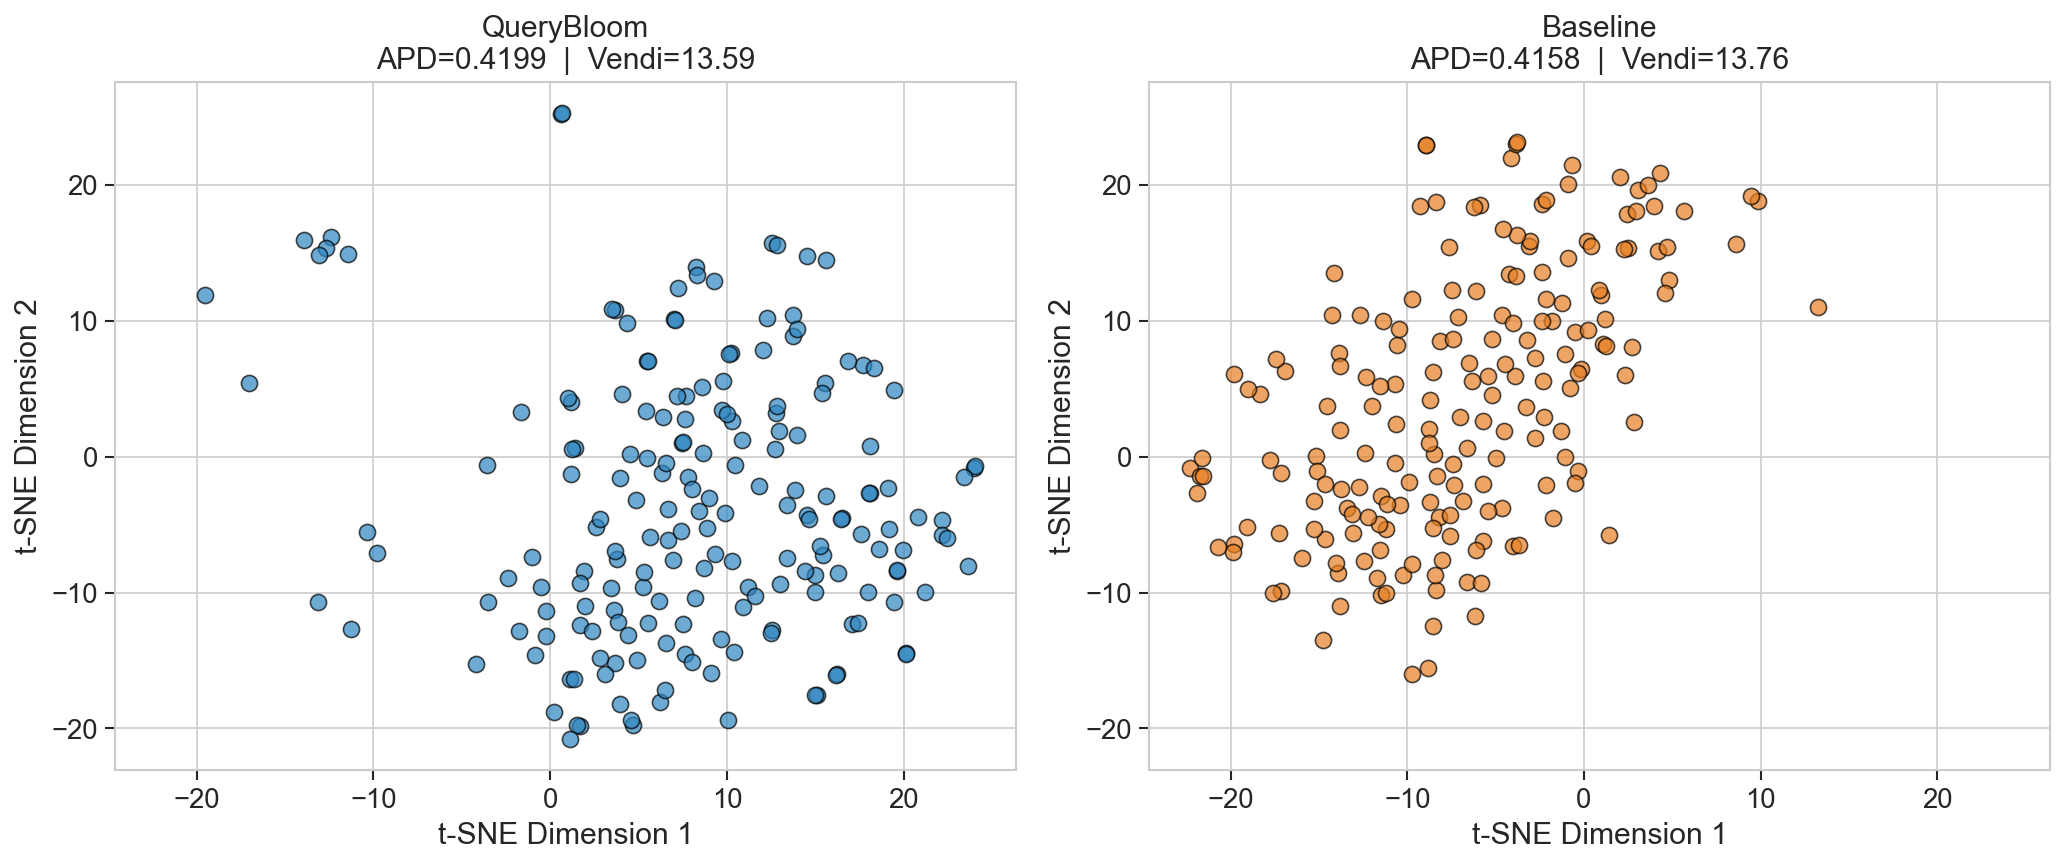

In [4]:
plot_semantic_embeddings(div1, div2, label1, label2, trim_outlier_pct=1)

In [12]:
import numpy as np
from metrics.diversity import embedding_diversity_metrics


def trimmed_embedding_metrics(metrics, trim_outlier_pct=5):
    embs = np.array(metrics["_embeddings"])
    centroid = embs.mean(axis=0)
    dists = np.linalg.norm(embs - centroid, axis=1)
    threshold = np.percentile(dists, 100 - trim_outlier_pct)
    trimmed = embs[dists <= threshold]
    apd_trimmed, vendi_trimmed = embedding_diversity_metrics(trimmed)
    return {
        "n_original": len(embs),
        "n_trimmed": len(trimmed),
        "removed": len(embs) - len(trimmed),
        "apd_original": metrics["apd"],
        "apd_trimmed": round(apd_trimmed, 4),
        "vendi_original": metrics["vendi"],
        "vendi_trimmed": round(vendi_trimmed, 4),
        "vendi_delta": round(vendi_trimmed - metrics["vendi"], 4),
    }

for label, metrics in [(label1, div1), (label2, div2)]:
    print(label)
    for key, value in trimmed_embedding_metrics(metrics, trim_outlier_pct=1).items():
        print(f"  {key}: {value}")
    print()

QueryBloom
  n_original: 191
  n_trimmed: 189
  removed: 2
  apd_original: 0.4199
  apd_trimmed: 0.4181
  vendi_original: 13.5938
  vendi_trimmed: 13.4376
  vendi_delta: -0.1562

Baseline
  n_original: 191
  n_trimmed: 189
  removed: 2
  apd_original: 0.4158
  apd_trimmed: 0.4136
  vendi_original: 13.7639
  vendi_trimmed: 13.5813
  vendi_delta: -0.1826



,pairs,mean,std,p05,p25,median,p75,p90,p95
QueryBloom,18145,0.4199,0.0570,0.3241,0.3833,0.4223,0.4585,0.4903,0.5097
Baseline,18145,0.4158,0.0601,0.3124,0.3778,0.4173,0.4563,0.4917,0.5121


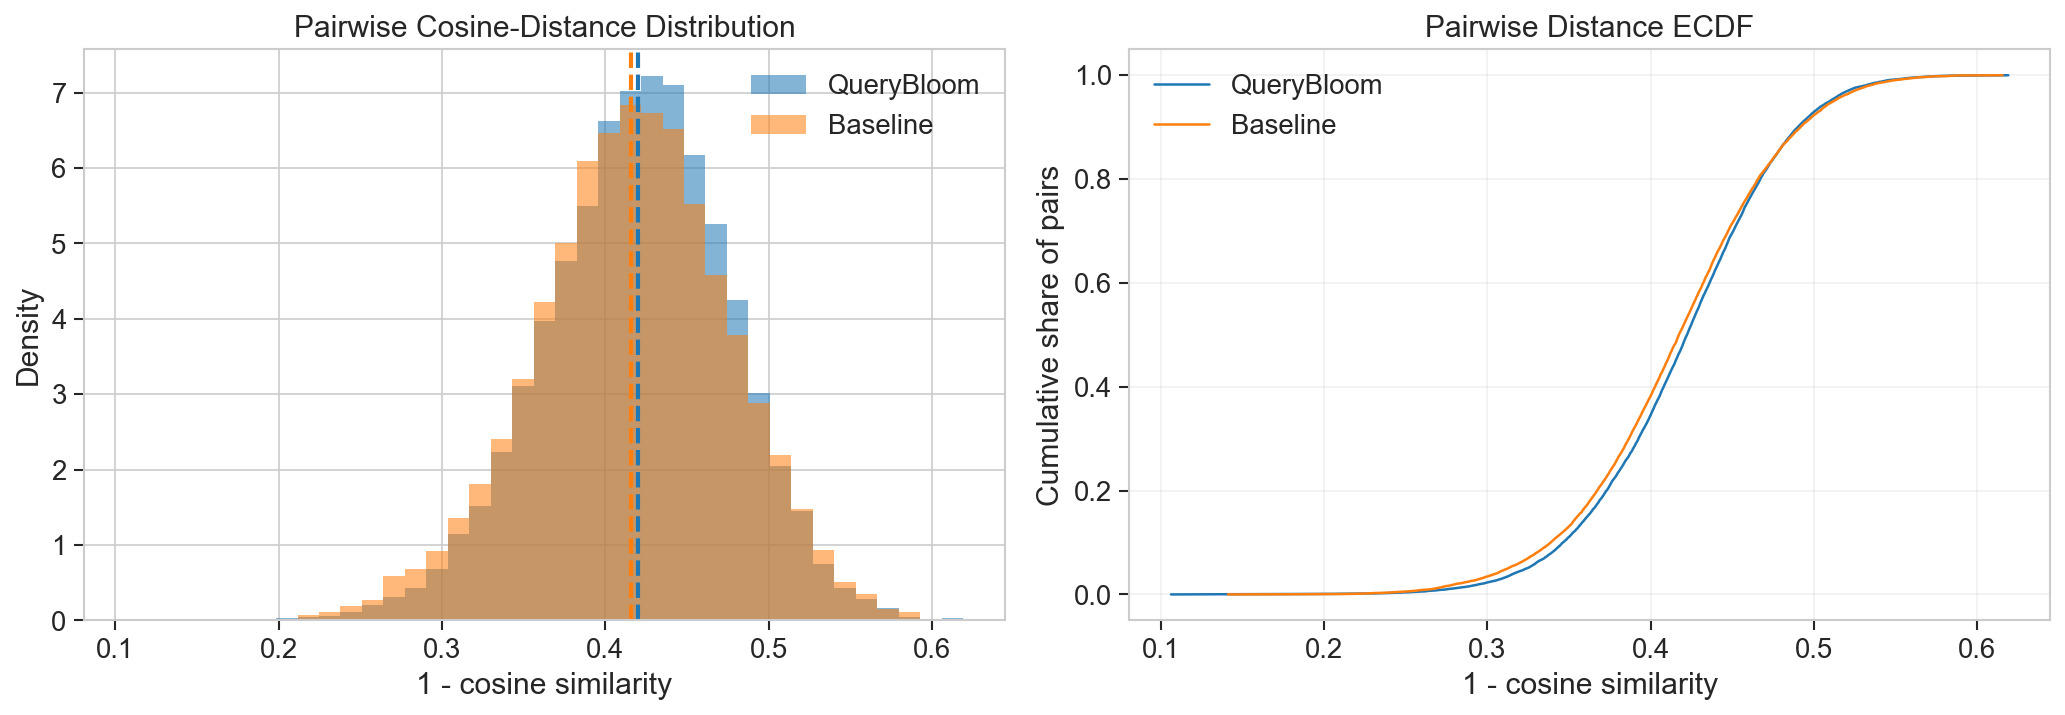

In [13]:
import matplotlib.pyplot as plt
import pandas as pd


def pairwise_cosine_distances(metrics):
    embs = np.array(metrics["_embeddings"])
    sim = embs @ embs.T
    mask = np.triu(np.ones(sim.shape, dtype=bool), k=1)
    return 1 - sim[mask]


def pairwise_distance_summary(distances):
    return {
        "pairs": len(distances),
        "mean": round(float(np.mean(distances)), 4),
        "std": round(float(np.std(distances)), 4),
        "p05": round(float(np.percentile(distances, 5)), 4),
        "p25": round(float(np.percentile(distances, 25)), 4),
        "median": round(float(np.median(distances)), 4),
        "p75": round(float(np.percentile(distances, 75)), 4),
        "p90": round(float(np.percentile(distances, 90)), 4),
        "p95": round(float(np.percentile(distances, 95)), 4),
    }

pw1 = pairwise_cosine_distances(div1)
pw2 = pairwise_cosine_distances(div2)

summary = pd.DataFrame(
    [pairwise_distance_summary(pw1), pairwise_distance_summary(pw2)],
    index=[label1, label2],
)
display(summary)

bins = np.linspace(
    min(pw1.min(), pw2.min()),
    max(pw1.max(), pw2.max()),
    40,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(pw1, bins=bins, alpha=0.55, density=True, label=label1)
axes[0].hist(pw2, bins=bins, alpha=0.55, density=True, label=label2)
axes[0].axvline(np.mean(pw1), color="C0", linestyle="--", linewidth=2)
axes[0].axvline(np.mean(pw2), color="C1", linestyle="--", linewidth=2)
axes[0].set_title("Pairwise Cosine-Distance Distribution")
axes[0].set_xlabel("1 - cosine similarity")
axes[0].set_ylabel("Density")
axes[0].legend()

for distances, label in [(pw1, label1), (pw2, label2)]:
    sorted_distances = np.sort(distances)
    cumulative = np.arange(1, len(sorted_distances) + 1) / len(sorted_distances)
    axes[1].plot(sorted_distances, cumulative, label=label)

axes[1].set_title("Pairwise Distance ECDF")
axes[1].set_xlabel("1 - cosine similarity")
axes[1].set_ylabel("Cumulative share of pairs")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Figure 2 — Structural & Complexity Diversity

Three panels: (a) SPARQL feature distribution bars, (b) complexity-spread violins, (c) template / entity diversity scalars.

/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/grasp/ABSTAT/analyze/plots/diversity_plots.py:534: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


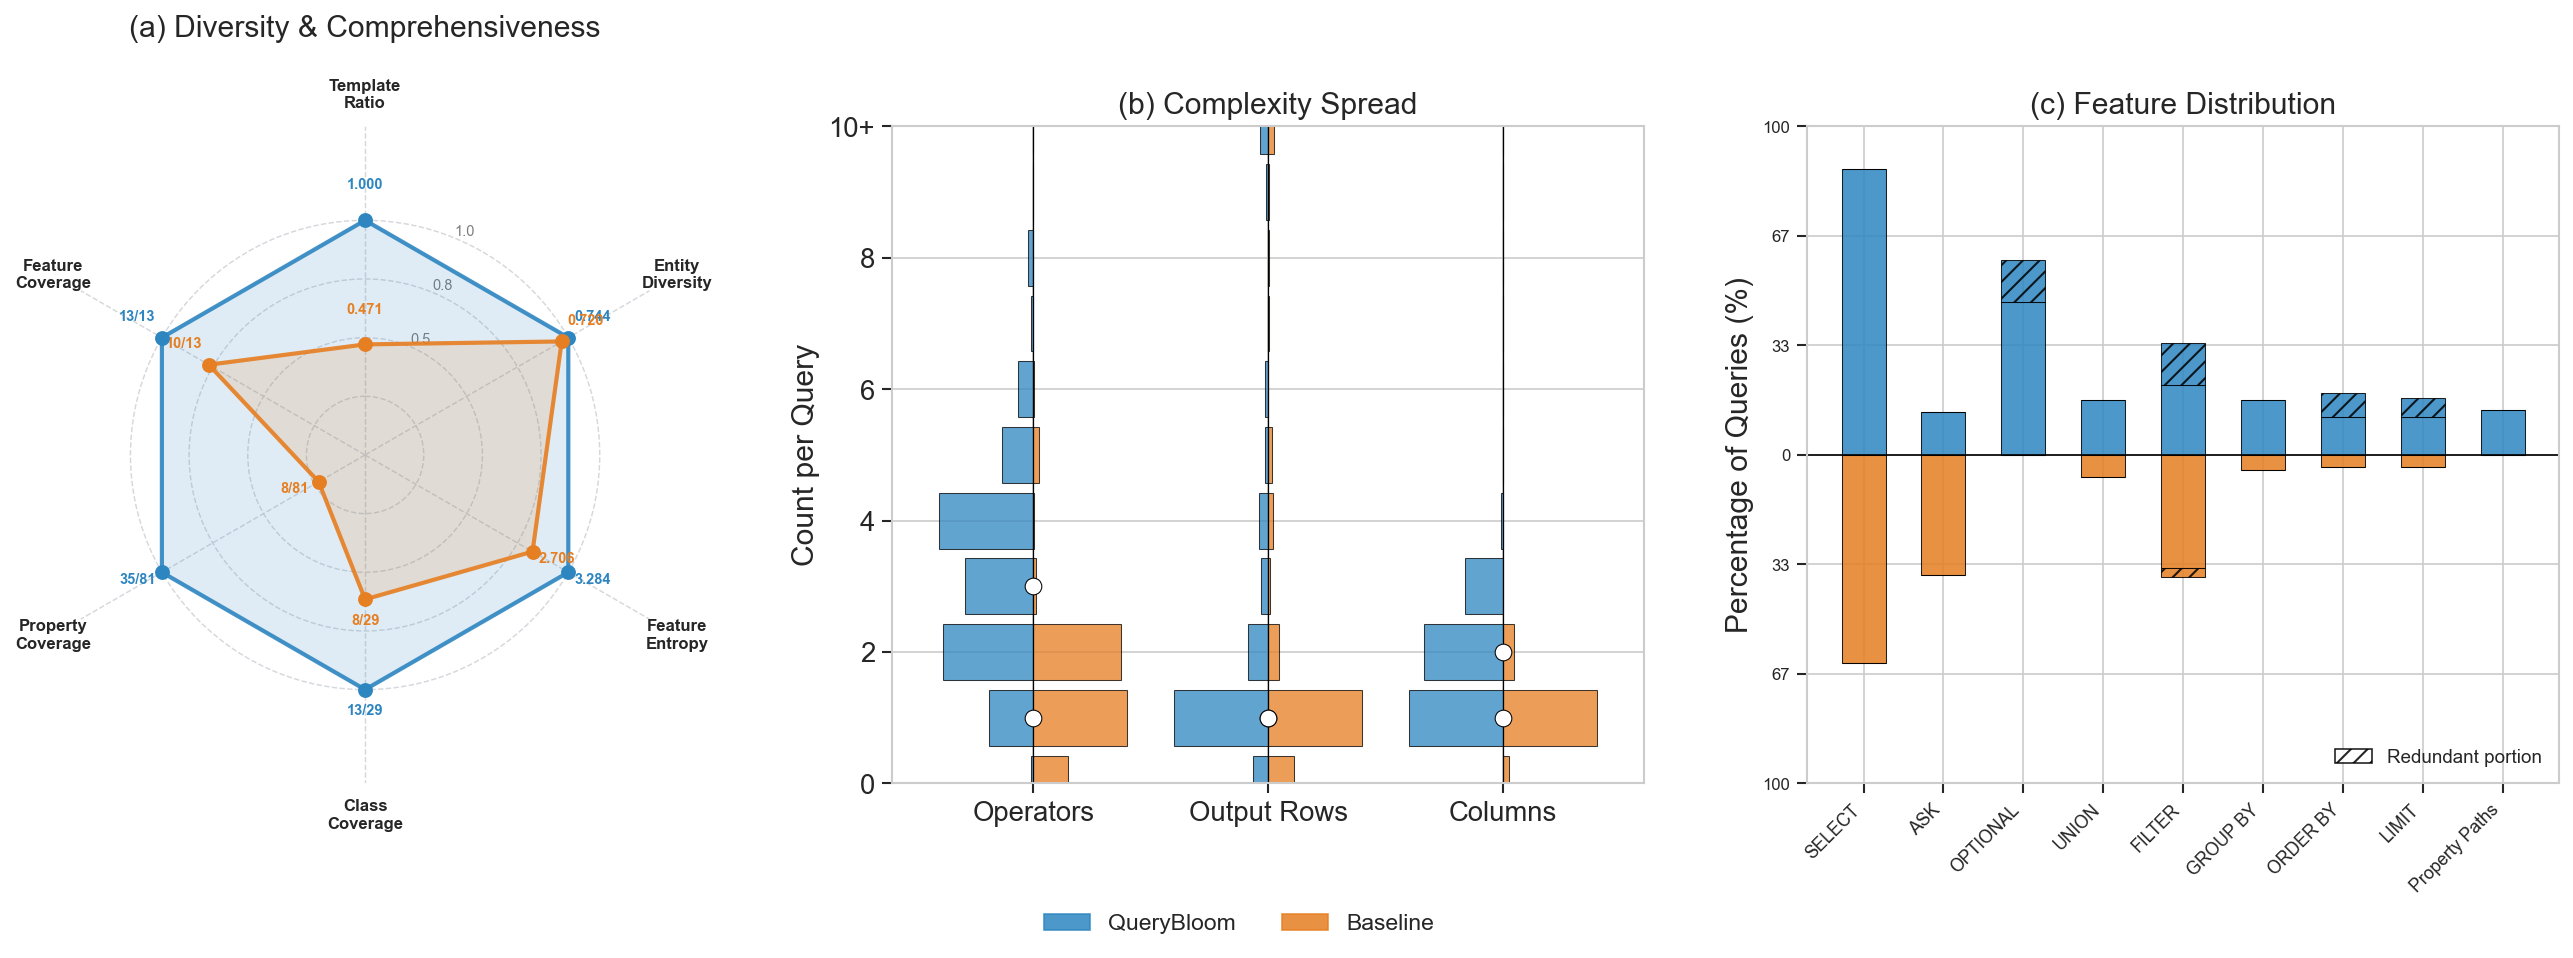

In [5]:
plot_structural_diversity(div1, div2, label1, label2, red1=red1, red2=red2, complexity_spread="histogram", comp1=comp1, comp2=comp2)

## Figure 3b — Coverage Gaps Table

Random sample of classes and properties unique to one benchmark or missing from both.

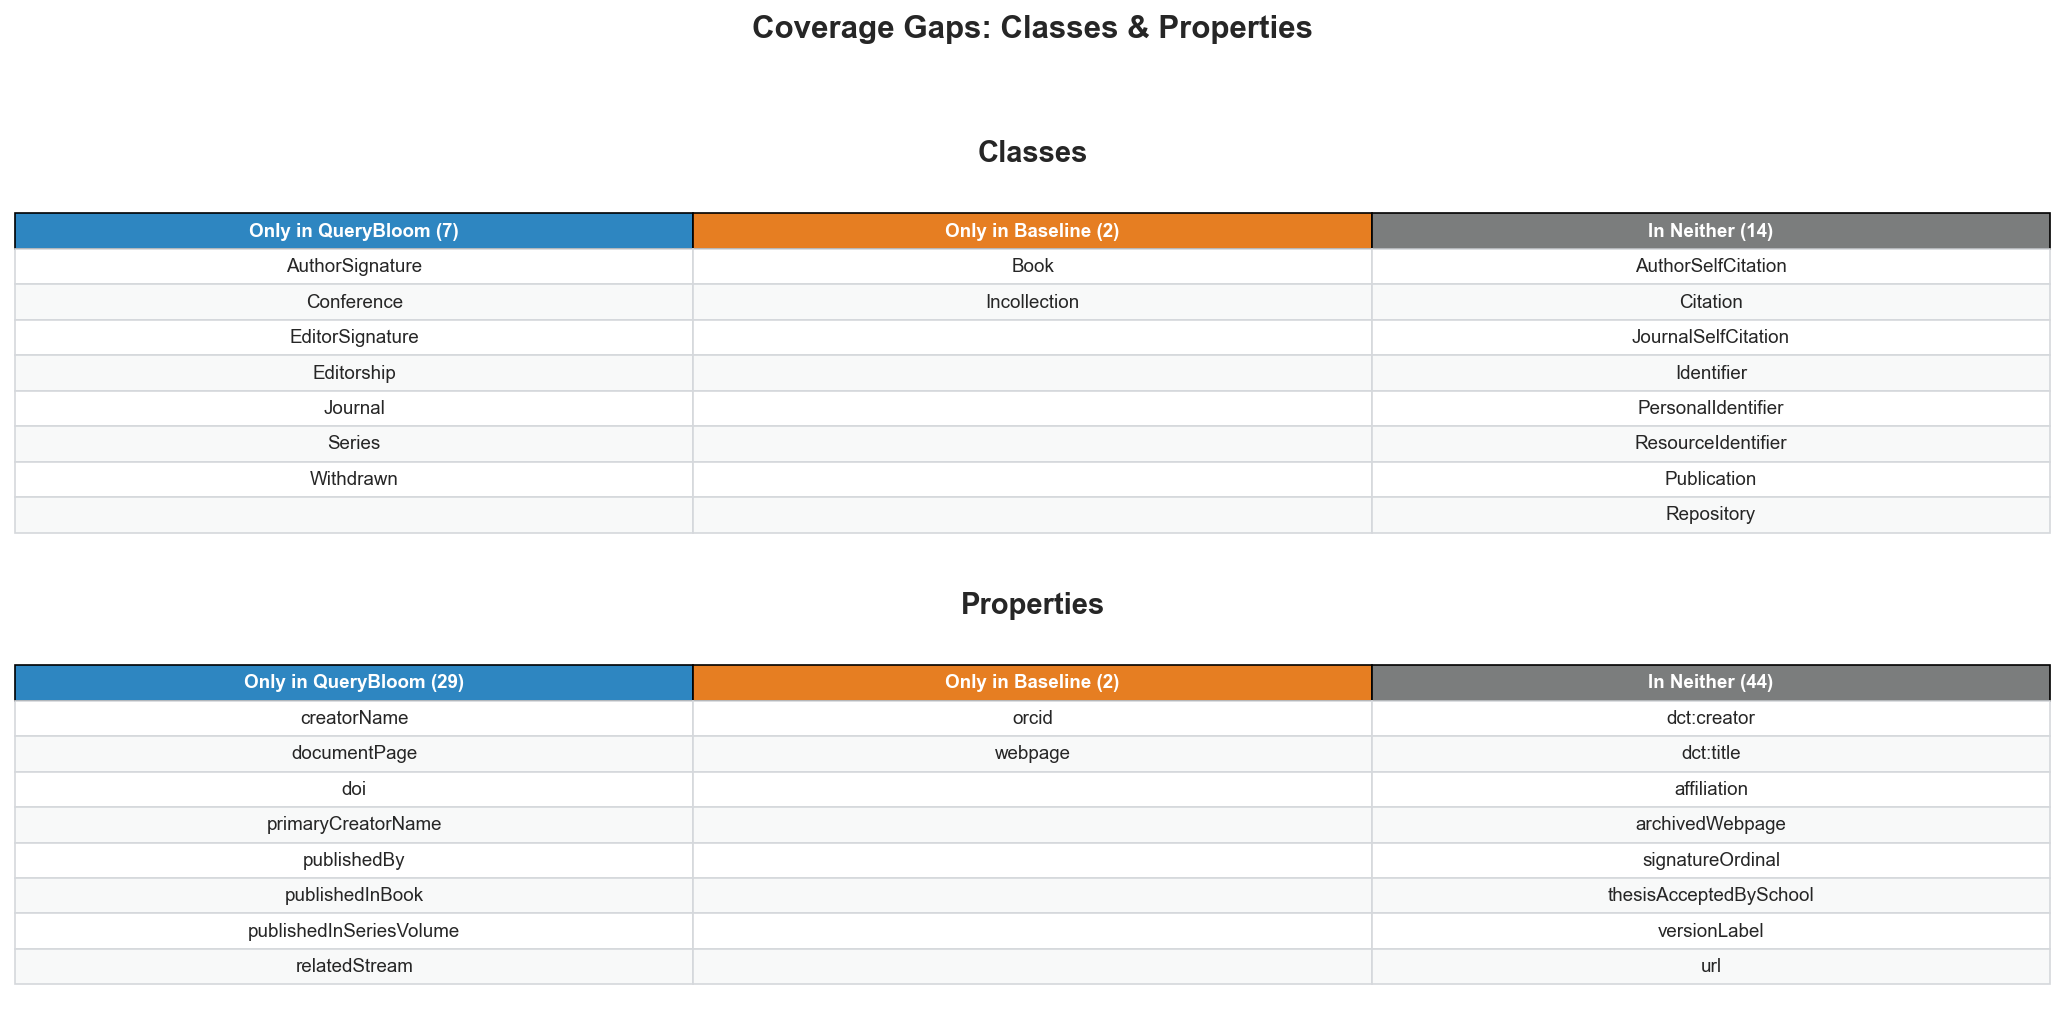

In [6]:
plot_coverage_table(queries1, queries2, kg_name, label1, label2, endpoint=endpoint)

In [7]:
show_redundancy_examples(queries1, questions1, query_endpoint)

Detecting redundant queries …
  Running / loading 351 unique queries …


NL Question,SPARQL Query
Which informal publications were authored by the ambiguous author entry “Yan Luo” and published in CoRR (up to 50 results)?,"PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?work ?title ?venue WHERE { BIND(<https://dblp.org/pid/25/2208> AS ?amb) ?work a dblp:Informal ; dblp:authoredBy ?amb . OPTIONAL { ?work dblp:title ?title } OPTIONAL { ?work dblp:publishedIn ?venue } FILTER(?venue = ""CoRR"") } ORDER BY LCASE(STR(COALESCE(?title, STR(?work)))) LIMIT 50"
"Which authors of “On the uniform one-dimensional fragment” (2016) have authored more than one informal publication, and how many informal publications has each authored in total?",PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?author ?authorName ?informalCount WHERE { VALUES ?work { <https://dblp.org/rec/journals/corr/Kuusisto16> } ?work a dblp:Informal ; dblp:authoredBy ?author . OPTIONAL { ?author a dblp:Person ; dblp:primaryCreatorName ?authorName } { SELECT ?author (COUNT(DISTINCT ?w2) AS ?informalCount) WHERE { ?w2 a dblp:Informal ; dblp:authoredBy ?author . } GROUP BY ?author } FILTER(?informalCount > 1) }
Which articles attributed to the ambiguous-name author 'Cong Yu' were published in 2024 or later?,"PREFIX dblp: <https://dblp.org/rdf/schema#> PREFIX xsd: <http://www.w3.org/2001/XMLSchema#> SELECT ?article ?title ?year WHERE { BIND(<https://dblp.org/pid/381/7284> AS ?creator) ?article a dblp:Article ; dblp:createdBy ?creator . OPTIONAL { ?article dblp:title ?title } OPTIONAL { ?article dblp:yearOfPublication ?year } FILTER(BOUND(?year) && ?year >= ""2024""^^xsd:gYear) } ORDER BY ?year LCASE(STR(?title))"
"What are up to 10 CoRR publications by Kevin Wang, and, when available, what is each title?","PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?work ?title WHERE { ?work a dblp:Informal ; dblp:authoredBy <https://dblp.org/pid/05/2437> ; dblp:publishedIn ?venue . FILTER(?venue = ""CoRR"") OPTIONAL { ?work dblp:title ?title . } } LIMIT 10"
"Which authors of the conference paper ""Comparing mirrored mutations and active covariance matrix adaptation in the IPOP-CMA-ES on the noiseless BBOB testbed (2012)"" have also published at least one other conference paper in the same conference series?","PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?person ?name WHERE { ?sig a dblp:AuthorSignature ; dblp:signaturePublication <https://dblp.org/rec/conf/gecco/BrockhoffAH12c> ; dblp:signatureCreator ?person . OPTIONAL { ?person dblp:primaryCreatorName ?name } FILTER EXISTS { <https://dblp.org/rec/conf/gecco/BrockhoffAH12c> dblp:publishedInStream ?conf . ?otherSig a dblp:AuthorSignature ; dblp:signatureCreator ?person ; dblp:signaturePublication ?otherPaper . ?otherPaper a dblp:Inproceedings ; dblp:publishedInStream ?conf . FILTER(?otherPaper != <https://dblp.org/rec/conf/gecco/BrockhoffAH12c>) } } ORDER BY COALESCE(?name, STR(?person))"
NL Question,SPARQL Query
Which people either authored the paper “Component-Wise Mapping of Media-Needs to a Distributed Presentation Environment” (2004) or were editors of the proceedings it appears in?,"PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?person ?personName WHERE { BIND(<https://dblp.org/rec/conf/compsac/FeijsH04> AS ?paper) ?paper a dblp:Inproceedings ; (dblp:authoredBy | dblp:publishedAsPartOf/dblp:hasSignature/dblp:signatureCreator) ?person . OPTIONAL { ?person dblp:creatorname ?personName . } } ORDER BY COALESCE(?personName, STR(?person))"
"For each person who authored papers that are part of the CMCS 2020 proceedings, how many such papers did they author?","PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT ?author ?authorName (COUNT(DISTINCT ?paper) AS ?paperCount) WHERE { ?paper a dblp:Inproceedings ; dblp:publishedAsPartOf <https://dblp.org/rec/conf/cmcs/2020> ; dblp:authoredBy ?author . OPTIONAL { ?author dblp:creatorname ?authorName . } } GROUP BY ?author ?authorName ORDER BY DESC(?paperCount) COALESCE(?authorName, STR(?author))"
"In whic

Done.
